# DESI-Y6 mock: the reconstruction with and without the bispectrum
The noiseless mock of 5_fisher_pk_bk.ipynb (7 samples, Y6-like volumes; truth = the fiducial ΛCDM): P0, P2, P4 for 0.01 < k < 0.2 h/Mpc, alone (`MI_DATA=y6_p`) or with the tree-level bispectrum monopole on closed triangles 0.02 ≤ k ≤ 0.10 h/Mpc (`MI_DATA=y6_pb`, pybird-dev). Matched: the same P(k) data and covariance, template (`bao_template_no_rs`), MI and EFT priors and map; the bispectrum adds its data and its two EFT parameters (profiled). No BAO points, no window. DESI-alone priors: BBN ω_b, n_s ~ N(0.9649, 0.042).

Recovered parameters: both MI best fits and the direct ΛCDM best fit return the truth, χ² = 0.00 (0.01 for the direct fit). Uncertainties: the Gauss–Newton Fisher at each best fit (`run.py fisher`), MI prior included, propagated to ΛCDM and w0waCDM.

Not done: chains. NUTS through pybird-dev costs 0.3–0.5 s per leapfrog step even without the bispectrum (13 ms on DR1 with the loop emulator), and short warm-ups leave 74–80% divergent steps; weighting P-alone draws to P + B has an effective fraction of 10⁻²¹ (from the two Fishers). So the prior-volume shifts of the marginals, seen on the DR1 mocks of 8_validation.ipynb, are not quantified here.

In [1]:
import sys; sys.path.insert(0, '../mi')
import plots as P
P.OPTS = ('bao_template_no_rs',)

## What the bispectrum adds
sd(P + B) / sd(P) of every MI parameter. Blue: measured by P alone.

block                    sd(P+B)/sd(P): median    best    measured by P (sd < 0.5 prior)
ln a (nodes)                              0.89    0.87                           0 of 21
ln f                                      0.27    0.22                            1 of 6
alphas                                    0.86    0.81                          12 of 12
ln D ratios                               0.72    0.71                            0 of 5
BAO amplitude A                           0.65    0.65                            1 of 1
wiggle damping dSigma^2 [Mpc^2]                    0.91    0.91                            0 of 1
LCDM     sd P alone: omega_cdm 0.0040, omega_b 0.0005, n_s 0.0249, lnAs 0.0679, h 0.0060
         sd(P+B)/sd(P): omega_cdm 0.78, omega_b 0.97, n_s 0.81, lnAs 0.61, h 0.86
w0waCDM  sd P alone: omega_cdm 0.0047, omega_b 0.0005, n_s 0.0281, lnAs 0.1080, h 0.0211, w0 0.2266, wa 0.7402
         sd(P+B)/sd(P): omega_cdm 0.71, omega_b 0.97, n_s 0.75, lnAs 0.60, h 0.90, w0 

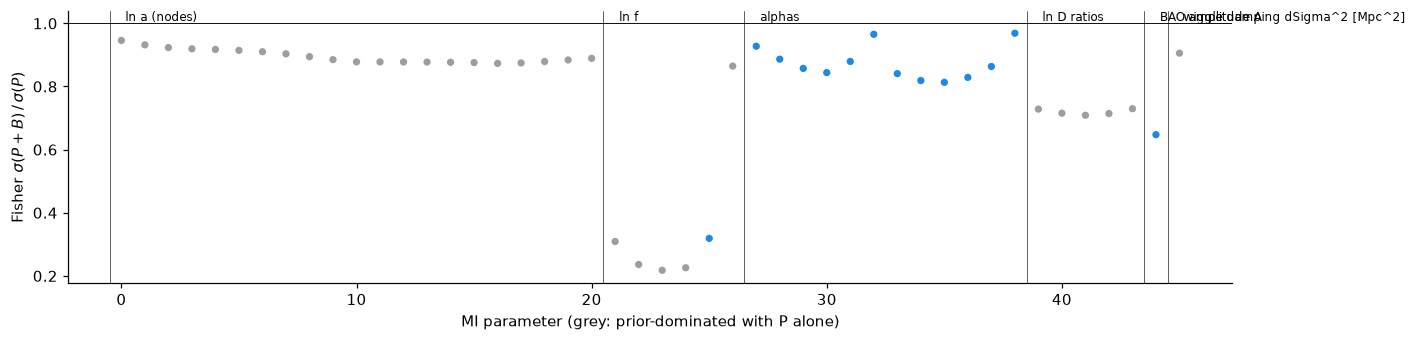

In [2]:
P.y6_fisher();